# NLP - Natural language Processing

In [22]:
sentence = "My organisation name is Deloitte. It is too far from my hometown bankura"
lowered_sentence = sentence.lower()
print(lowered_sentence)

my organisation name is deloitte. it is too far from my hometown bankura


### Data Pre-Processing

In [23]:
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/souvikmaji/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [24]:
en_stopwords = stopwords.words('english')
print(en_stopwords)

['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been', 'before', 'being', 'below', 'between', 'both', 'but', 'by', 'can', 'couldn', "couldn't", 'd', 'did', 'didn', "didn't", 'do', 'does', 'doesn', "doesn't", 'doing', 'don', "don't", 'down', 'during', 'each', 'few', 'for', 'from', 'further', 'had', 'hadn', "hadn't", 'has', 'hasn', "hasn't", 'have', 'haven', "haven't", 'having', 'he', "he'd", "he'll", 'her', 'here', 'hers', 'herself', "he's", 'him', 'himself', 'his', 'how', 'i', "i'd", 'if', "i'll", "i'm", 'in', 'into', 'is', 'isn', "isn't", 'it', "it'd", "it'll", "it's", 'its', 'itself', "i've", 'just', 'll', 'm', 'ma', 'me', 'mightn', "mightn't", 'more', 'most', 'mustn', "mustn't", 'my', 'myself', 'needn', "needn't", 'no', 'nor', 'not', 'now', 'o', 'of', 'off', 'on', 'once', 'only', 'or', 'other', 'our', 'ours', 'ourselves', 'out', 'over', 'own', 're', 's', 'same', 'shan', "shan't", 'she

In [25]:
en_stopwords.append("my")
no_stopwords = [word for word in lowered_sentence.split() if word not in en_stopwords]
sentence_no_stopwords = ' '.join(no_stopwords)
print(sentence_no_stopwords)

organisation name deloitte. far hometown bankura


In [26]:
import re
customer_service = [
    "Souvik contacted customer service about his account.",
    "Shouvik requested help with resetting the password, he quickly adapted",
    "The representative assisted him with the billing issue.",
    "Customer service followed up with Shouvik the next day, is it done ?"
]

search_pattern = r"Sh?ouvik"
find_pattern = r"^S"
pipe_pattern = r"(request|assist)ed"
no_punctuation_pattern = r"[^\w\s]"     # means find anything which is not a word or not a whitespace

souvik_reviews = []
for review in customer_service:
    if (re.search(pipe_pattern, review)):
        souvik_reviews.append(review)

# print(souvik_reviews)

no_punctuation_sentence = []
for review in customer_service:
    no_punc_string = re.sub(no_punctuation_pattern, "", review)
    no_punctuation_sentence.append(no_punc_string)
print(no_punctuation_sentence)


['Souvik contacted customer service about his account', 'Shouvik requested help with resetting the password he quickly adapted', 'The representative assisted him with the billing issue', 'Customer service followed up with Shouvik the next day is it done ']


### Tokenization

In [27]:
import nltk
nltk.download('punkt_tab')
from nltk.tokenize import word_tokenize, sent_tokenize

[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/souvikmaji/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


In [34]:
sentences = "Her cat's name is Luna. Her dog's name is Max"

In [35]:
sent_tokenize(sentences)

["Her cat's name is Luna.", "Her dog's name is Max"]

In [36]:
word_tokenize(sentences)

['Her',
 'cat',
 "'s",
 'name',
 'is',
 'Luna',
 '.',
 'Her',
 'dog',
 "'s",
 'name',
 'is',
 'Max']

### Standardisation - Stemming and Lemmatization
Stemming - reduce english words to a simpler base. but sometimes it creates a base word which doesn't have any meaning.
Lemmatization - Advance version of Stemming where the base word will always be a meaningful and gramartically correct word.

In [46]:
from nltk.stem import PorterStemmer
# PorterStemmer is a classic role-based algorithm that reduce english words to a simpler base.

nltk.download('wordnet')
from nltk.stem import WordNetLemmatizer

[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/souvikmaji/nltk_data...


In [47]:
ps= PorterStemmer()
lm = WordNetLemmatizer()

In [49]:
connect_tokens = ['connecting', 'connected', 'connectivity', 'connect', 'connects', 'connector', 'connectors', 'like', 'better', 'worse']

In [53]:
print("Stemmetize\n")
for t in connect_tokens:
    print(t, ": ", ps.stem(t))
print("\nLemmatize\n")
for t in connect_tokens:
    print(t, ": ", lm.lemmatize(t))

Stemmetize

connecting :  connect
connected :  connect
connectivity :  connect
connect :  connect
connects :  connect
connector :  connector
connectors :  connector
like :  like
better :  better
worse :  wors

Lemmatize

connecting :  connecting
connected :  connected
connectivity :  connectivity
connect :  connect
connects :  connects
connector :  connector
connectors :  connector
like :  like
better :  better
worse :  worse


### N-Grams
Helps us to analyze not just individual words but also the relationship between neighboring words

In [54]:
import nltk
import pandas as pd 
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [111]:
paragraph = "Trinamool Congress leader Mahua Moitra has moved the Supreme Court against her expulsion from the Lok Sabha over the cash-for-query allegations against her. Moitra was ousted from the Parliament last week after the Ethics Committee of the Lok Sabha found her guilty of jeopardising national security by sharing her parliamentary portal's login credentials with businessman Darshan Hiranandani."
no_pun_paragraph = re.sub(no_punctuation_pattern, "", paragraph)
word_tokens = word_tokenize(no_pun_paragraph)

print(word_tokens)

['Trinamool', 'Congress', 'leader', 'Mahua', 'Moitra', 'has', 'moved', 'the', 'Supreme', 'Court', 'against', 'her', 'expulsion', 'from', 'the', 'Lok', 'Sabha', 'over', 'the', 'cashforquery', 'allegations', 'against', 'her', 'Moitra', 'was', 'ousted', 'from', 'the', 'Parliament', 'last', 'week', 'after', 'the', 'Ethics', 'Committee', 'of', 'the', 'Lok', 'Sabha', 'found', 'her', 'guilty', 'of', 'jeopardising', 'national', 'security', 'by', 'sharing', 'her', 'parliamentary', 'portals', 'login', 'credentials', 'with', 'businessman', 'Darshan', 'Hiranandani']


In [112]:
unigrams = (pd.Series(nltk.ngrams(word_tokens, 1)).value_counts())
print(unigrams[:11])

(the,)          6
(her,)          4
(Moitra,)       2
(against,)      2
(from,)         2
(Lok,)          2
(Sabha,)        2
(of,)           2
(Trinamool,)    1
(Congress,)     1
(leader,)       1
Name: count, dtype: int64


Text(0.5, 1.0, '10 most frequently occuring unigrams')

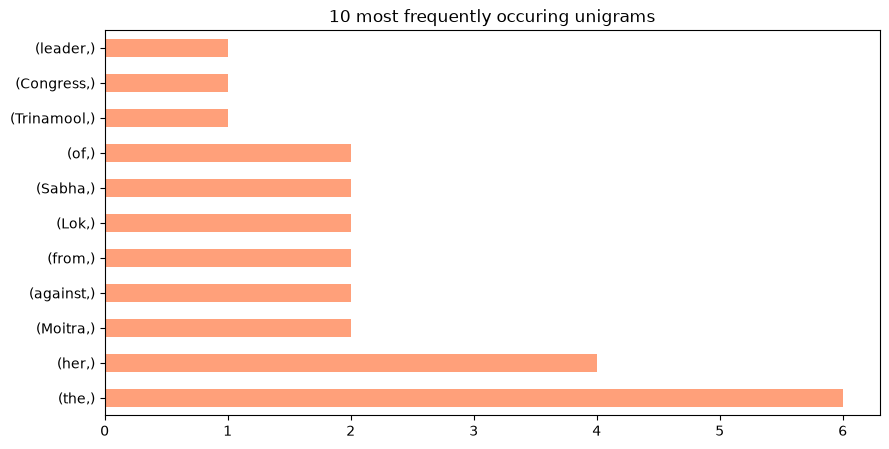

In [113]:
unigrams[:11].plot.barh(color="lightsalmon", width=.5, figsize=(10,5))
plt.title("10 most frequently occuring unigrams")

In [114]:
bigrams = (pd.Series(nltk.ngrams(word_tokens, 2)).value_counts())
print(bigrams[:10])

trigrams = (pd.Series(nltk.ngrams(word_tokens, 3)).value_counts())
print(trigrams[:10])

(against, her)           2
(from, the)              2
(the, Lok)               2
(Lok, Sabha)             2
(Trinamool, Congress)    1
(Congress, leader)       1
(leader, Mahua)          1
(Mahua, Moitra)          1
(Moitra, has)            1
(has, moved)             1
Name: count, dtype: int64
(the, Lok, Sabha)                2
(Trinamool, Congress, leader)    1
(Congress, leader, Mahua)        1
(leader, Mahua, Moitra)          1
(Mahua, Moitra, has)             1
(Moitra, has, moved)             1
(has, moved, the)                1
(moved, the, Supreme)            1
(the, Supreme, Court)            1
(Supreme, Court, against)        1
Name: count, dtype: int64


### POS (Parts of Speech) Tagging and NER (Named Entity Recognition)

In [90]:
import spacy

In [91]:
nlp = spacy.load("en_core_web_sm")

In [115]:
spacy_document = nlp(no_pun_paragraph)
for token in spacy_document:
    print(token.text, "-", token.pos_)

Trinamool - PROPN
Congress - PROPN
leader - NOUN
Mahua - PROPN
Moitra - PROPN
has - AUX
moved - VERB
the - DET
Supreme - PROPN
Court - PROPN
against - ADP
her - PRON
expulsion - NOUN
from - ADP
the - DET
Lok - PROPN
Sabha - PROPN
over - ADP
the - DET
cashforquery - NOUN
allegations - NOUN
against - ADP
her - PRON
Moitra - PROPN
was - AUX
ousted - VERB
from - ADP
the - DET
Parliament - PROPN
last - ADJ
week - NOUN
after - SCONJ
the - DET
Ethics - PROPN
Committee - PROPN
of - ADP
the - DET
Lok - PROPN
Sabha - PROPN
found - VERB
her - PRON
guilty - ADJ
of - ADP
jeopardising - VERB
national - ADJ
security - NOUN
by - ADP
sharing - VERB
her - PRON
parliamentary - ADJ
portals - NOUN
login - VERB
credentials - NOUN
with - ADP
businessman - NOUN
Darshan - PROPN
Hiranandani - PROPN


In [116]:
pos_df = pd.DataFrame(columns=['token','pos_tag'])
for token in spacy_document:
    pos_df = pd.concat([pos_df,
                        pd.DataFrame.from_records([{
                            'token': token.text,
                            'pos_tag': token.pos_
                        }])], ignore_index=True)
pos_df.head(15)

,token,pos_tag
0,Trinamool,PROPN
1,Congress,PROPN
2,leader,NOUN
3,Mahua,PROPN
4,Moitra,PROPN
5,has,AUX
6,moved,VERB
7,the,DET
8,Supreme,PROPN
9,Court,PROPN


In [117]:
pos_df_count = pos_df.groupby(['token', 'pos_tag']).size().reset_index(name='counts').sort_values(by='counts', ascending=False)
print(pos_df_count)

            token pos_tag  counts
39            the     DET       6
25            her    PRON       4
14        against     ADP       2
22           from     ADP       2
6             Lok   PROPN       2
8          Moitra   PROPN       2
10          Sabha   PROPN       2
32             of     ADP       2
26   jeopardising    VERB       1
27           last     ADJ       1
28         leader    NOUN       1
29          login    VERB       1
30          moved    VERB       1
31       national     ADJ       1
0       Committee   PROPN       1
33         ousted    VERB       1
24            has     AUX       1
35  parliamentary     ADJ       1
36        portals    NOUN       1
37       security    NOUN       1
38        sharing    VERB       1
40            was     AUX       1
41           week    NOUN       1
34           over     ADP       1
21          found    VERB       1
23         guilty     ADJ       1
1        Congress   PROPN       1
2           Court   PROPN       1
3         Dars

In [118]:
pos_df_poscounts = pos_df_count.groupby(['pos_tag'])['token'].count().sort_values(ascending=False)
print(pos_df_poscounts)

pos_tag
PROPN    13
NOUN      9
ADP       6
VERB      6
ADJ       4
AUX       2
DET       1
PRON      1
SCONJ     1
Name: token, dtype: int64


In [119]:
nouns = pos_df_count[pos_df_count.pos_tag == 'NOUN']
print(nouns)

           token pos_tag  counts
28        leader    NOUN       1
36       portals    NOUN       1
37      security    NOUN       1
41          week    NOUN       1
15   allegations    NOUN       1
16   businessman    NOUN       1
18  cashforquery    NOUN       1
19   credentials    NOUN       1
20     expulsion    NOUN       1


In [106]:
from spacy import displacy
from spacy import tokenizer
from IPython.display import HTML, display
import re

In [120]:
for word in spacy_document.ents:
    print(word.text, "-", word.label_)

Trinamool Congress - ORG
Mahua Moitra - PERSON
the Supreme Court - ORG
Moitra - NORP
Parliament - ORG
last week - DATE
the Ethics Committee - ORG
Darshan Hiranandani - PERSON


In [124]:
html = displacy.render(spacy_document, style="ent", jupyter=False)
display(HTML(html))

# Sentiment Analysis

In [144]:
sentence1 = "I absolutely love the new design of your website, it is so fast and easy to use!"
sentence2 = "My order arrived three weeks late, and the item was completely broken."
sentence3 = "The package was delivered to my front door this morning."
sentence4 = "The food quality is great, but the service was extremely slow."
sentences_list = [sentence1, sentence2, sentence3, sentence4]
print(sentences_list)


['I absolutely love the new design of your website, it is so fast and easy to use!', 'My order arrived three weeks late, and the item was completely broken.', 'The package was delivered to my front door this morning.', 'The food quality is great, but the service was extremely slow.']


### TextBlob

In [139]:
from textblob import TextBlob
sentiment_score_list = []
for sentence in sentences_list:
    sentiment_score = TextBlob(sentence)
    sentiment_score_list.append(sentiment_score.sentiment.polarity)
print(sentiment_score_list)

[0.3445075757575758, -0.35, 0.0, 0.75]


### Vader

In [134]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
vader_sentiment = SentimentIntensityAnalyzer()

In [146]:
for sentence in sentences_list:
    print(vader_sentiment.polarity_scores(sentence))

{'neg': 0.0, 'neu': 0.654, 'pos': 0.346, 'compound': 0.838}
{'neg': 0.236, 'neu': 0.764, 'pos': 0.0, 'compound': -0.5256}
{'neg': 0.0, 'neu': 1.0, 'pos': 0.0, 'compound': 0.0}
{'neg': 0.0, 'neu': 0.797, 'pos': 0.203, 'compound': 0.3716}


### Pre-trained Transformer

In [141]:
import transformers
from transformers import pipeline

In [142]:
sentiment_pipeline = pipeline("sentiment-analysis")

[transformers] No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.
Loading weights: 100%|██████████| 104/104 [00:00<00:00, 8352.63it/s]
0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.


In [145]:
for sentence in sentences_list:
    print(sentiment_pipeline(sentence))

[{'label': 'POSITIVE', 'score': 0.9998559951782227}]
[{'label': 'NEGATIVE', 'score': 0.9996604919433594}]
[{'label': 'POSITIVE', 'score': 0.5317838191986084}]
[{'label': 'NEGATIVE', 'score': 0.9987611770629883}]
